In [ ]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install py3Dmol
      !pip install rdkit
      pbar.update(50)
      from rdkit import Chem
      from rdkit.Chem import Draw
      from rdkit.Chem.Draw import IPythonConsole
      from rdkit.Chem import AllChem # import the AllChem submodule from the Chem module
      from rdkit.Chem import rdDistGeom
      from rdkit.Chem import rdDepictor
      from IPython.display import Image
      import py3Dmol


      pbar.update(50)

  0%|          | 0/100 [00:00<?, ?it/s]

## Convertir SMILES a representaciones 2D




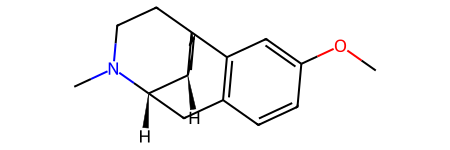

In [ ]:
d = Chem.MolFromSmiles('[H][C@]12CCCC[C@]11CCN(C)[C@H]2CC2=C1C=C(OC)C=C2')
d

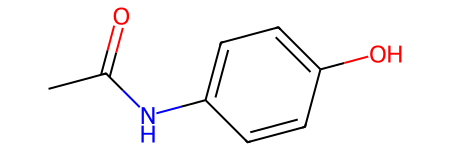

In [ ]:
paracetamol = Chem.MolFromSmiles('CC(=O)NC1=CC=C(C=C1)O')
paracetamol

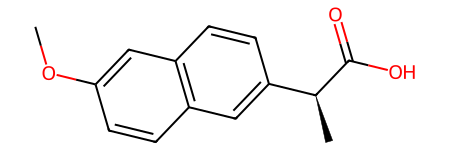

In [ ]:
naproxen = Chem.MolFromSmiles('C[C@@H](C1=CC2=C(C=C1)C=C(C=C2)OC)C(=O)O')
naproxen

## Conversión de la molécula en diferentes tipos de representaciones

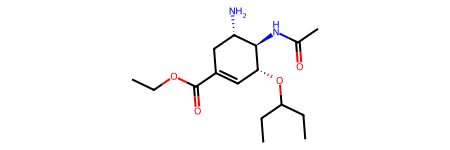

In [ ]:
oseltamivir = Chem.MolFromSmiles('CCC(CC)O[C@@H]1C=C(C[C@@H]([C@H]1NC(=O)C)N)C(=O)OCC')
oseltamivir

In [ ]:
Chem.MolToSmiles(oseltamivir)

'CCOC(=O)C1=C[C@@H](OC(CC)CC)[C@H](NC(C)=O)[C@@H](N)C1'

In [ ]:
Chem.MolToSmarts(oseltamivir)

'[#6]-[#6]-[#6](-[#6]-[#6])-[#8]-[#6@@H]1-[#6]=[#6](-[#6]-[#6@@H](-[#6@H]-1-[#7]-[#6](=[#8])-[#6])-[#7])-[#6](=[#8])-[#8]-[#6]-[#6]'

In [ ]:
Chem.MolToInchiKey(oseltamivir)

'VSZGPKBBMSAYNT-RRFJBIMHSA-N'

Para saber el número de átomos, utilizar la siguiente función.

In [ ]:
d.GetNumAtoms()

20

In [ ]:
paracetamol.GetNumAtoms()

11

In [ ]:
paracetamol.GetNumBonds()

11

## Estereoquímica en la representación 2D

In [ ]:
#De las siguientes funciones, la primera enumera a los átomos y la segunda le da estereoquímica a los compuestos.
IPythonConsole.drawOptions.addAtomIndices = True
IPythonConsole.drawOptions.addStereoAnnotation = True

In [ ]:
m1 = Chem.MolFromSmiles('C[C@H]1CCC[C@@H](C)[C@@H]1Cl')
m2 = Chem.MolFromSmiles('[H][C@@]1(OC(=O)C(O)=C1O)[C@@H](O)CO')

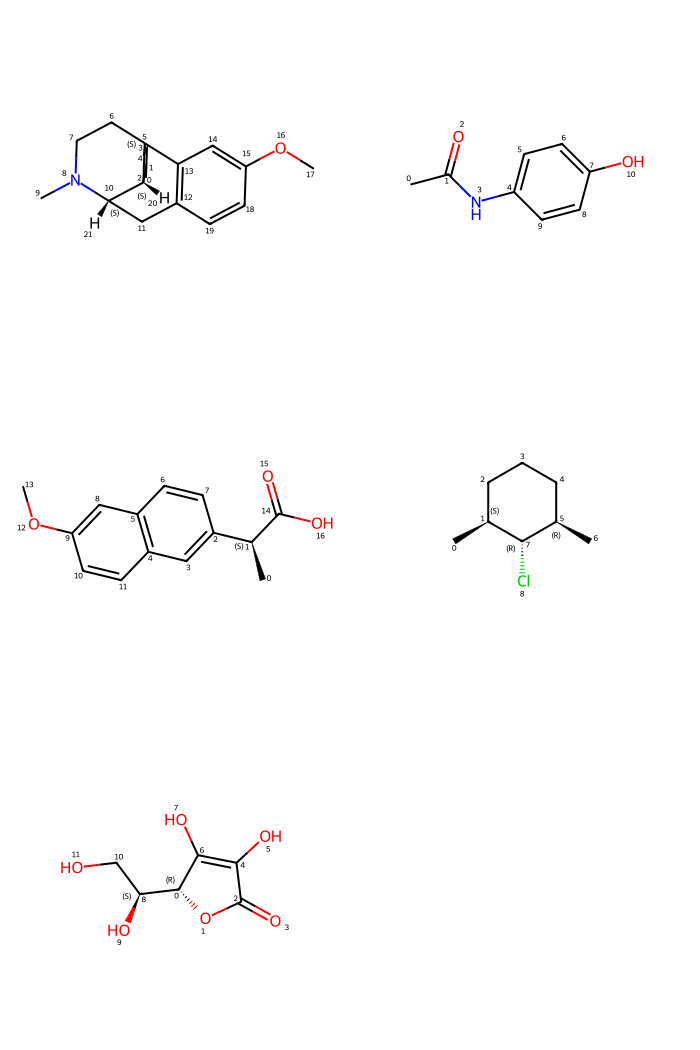

In [ ]:
Draw.MolsToGridImage((d, paracetamol, naproxen, m1,m2), subImgSize=(350,350), molsPerRow=2)

## Hacer una lista con SMILES

In [ ]:
smiles_list = ['CC1=CC=C(C=C1)S(=O)(=O)NC(=O)NN1CCCCCC1', 'N[C@@H](CCC(O)=O)C(O)=O', 'CCN(CC)CC#CCOC(=O)C(O)(C1CCCCC1)C1=CC=CC=C1']

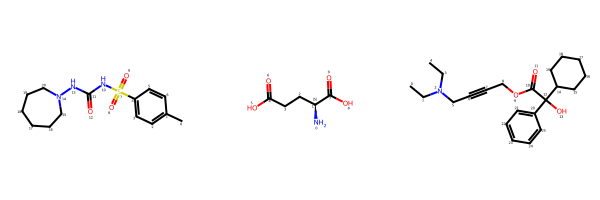

In [ ]:
mol_list = []
for smiles in smiles_list:
  mol = Chem.MolFromSmiles(smiles)
  mol_list.append(mol)

img = Draw.MolsToGridImage(mol_list)
img

In [ ]:
list_of_smiles = ['CC1=C2[C@H](C(=O)[C@@]3([C@H](C[C@@H]4[C@]([C@H]3[C@@H]([C@@](C2(C)C)(C[C@@H]1OC(=O)[C@@H]([C@H](C5=CC=CC=C5)NC(=O)C6=CC=CC=C6)O)O)OC(=O)C7=CC=CC=C7)(CO4)OC(=O)C)O)C)OC(=O)C',
                  'CCN(CC)C(=O)C1=CC(=C(C=C1)O)OC',
                  'CCN(CC)C(=S)SSC(=S)N(CC)CC']

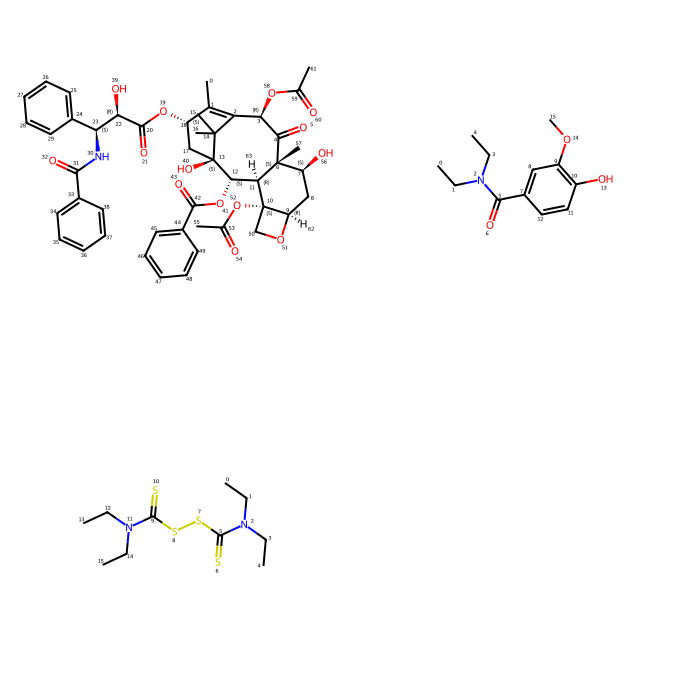

In [ ]:
mol_list_2 = []
for smiles in list_of_smiles:
  mol = Chem.MolFromSmiles(smiles)
  mol_list_2.append(mol)

img = Draw.MolsToGridImage(mol_list_2, molsPerRow=2, subImgSize= (350,350))
img

Para encontrar subestructuras en la lista:
1. Definir el *pattern* que se busca en los compuestos expresado como SMILES.
2. Utilizar las funciones descritas.

In [ ]:
pattern = Chem.MolFromSmiles ('SS')#'OCC-O', 'NC(N)=O', 'SS'
for mol in mol_list_2:
  print(mol.HasSubstructMatch(pattern))

False
False
True


#Covertir a SMARTS

In [ ]:
smarts = Chem.MolToSmarts(paracetamol)
smarts

'[#6]-[#6](=[#8])-[#7]-[#6]1:[#6]:[#6]:[#6](:[#6]:[#6]:1)-[#8]'

In [ ]:
def smiles_to_smarts(smiles_list):
  smarts_list = []
  for smiles in smiles_list:
    mol = Chem.MolFromSmiles(smiles)
    if mol:
      smarts = Chem.MolToSmarts(mol)
      smarts_list.append(smarts)
    else:
      smarts_list.append(None) # or handle the error as needed
  return smarts_list

In [ ]:
#smiles_list = ['C', 'CC', 'CCC', 'CCCC', 'CCCCCC', 'C1CCCCC1', 'C1=CC=CC=C1']
smiles_list = ['C', 'C=C', 'C=CC', 'C=CC=C', 'CC=CCCC', 'C1CCCCC1', 'C1=CC=CC=C1']
smarts_list = smiles_to_smarts(smiles_list)
smarts_list

['[#6]',
 '[#6]=[#6]',
 '[#6]=[#6]-[#6]',
 '[#6]=[#6]-[#6]=[#6]',
 '[#6]-[#6]=[#6]-[#6]-[#6]-[#6]',
 '[#6]1-[#6]-[#6]-[#6]-[#6]-[#6]-1',
 '[#6]1:[#6]:[#6]:[#6]:[#6]:[#6]:1']

In [ ]:
smiles_to_smarts(list_of_smiles)

['[#6]-[#6]1=[#6]2-[#6@H](-[#6](=[#8])-[#6@@]3(-[#6@H](-[#6]-[#6@@H]4-[#6@](-[#6@H]-3-[#6@@H](-[#6@@](-[#6]-2(-[#6])-[#6])(-[#6]-[#6@@H]-1-[#8]-[#6](=[#8])-[#6@@H](-[#6@H](-[#6]1:[#6]:[#6]:[#6]:[#6]:[#6]:1)-[#7]-[#6](=[#8])-[#6]1:[#6]:[#6]:[#6]:[#6]:[#6]:1)-[#8])-[#8])-[#8]-[#6](=[#8])-[#6]1:[#6]:[#6]:[#6]:[#6]:[#6]:1)(-[#6]-[#8]-4)-[#8]-[#6](=[#8])-[#6])-[#8])-[#6])-[#8]-[#6](=[#8])-[#6]',
 '[#6]-[#6]-[#7](-[#6]-[#6])-[#6](=[#8])-[#6]1:[#6]:[#6](:[#6](:[#6]:[#6]:1)-[#8])-[#8]-[#6]',
 '[#6]-[#6]-[#7](-[#6]-[#6])-[#6](=[#16])-[#16]-[#16]-[#6](=[#16])-[#7](-[#6]-[#6])-[#6]-[#6]']

## Resaltar subestructuras

In [ ]:
m = Chem.MolFromSmiles('CC1=C(C)C2=C(CCC(C)(COC3=CC=C(CC4SC(=O)NC4=O)C=C3)O2)C(C)=C1O')

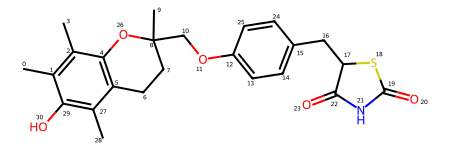

In [ ]:
m

((19, 20, 18),)


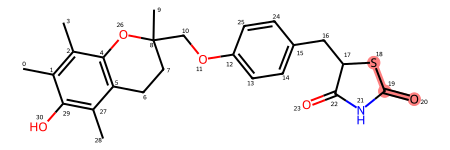

In [ ]:
substructure = Chem.MolFromSmarts('C(=O)S')
print(m.GetSubstructMatches(substructure))
m

In [ ]:
def smi2conf(smiles):
    '''Convert SMILES to rdkit.Mol with 3D coordinates'''
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        mol = Chem.AddHs(mol)
        AllChem.EmbedMolecule(mol)
        AllChem.MMFFOptimizeMolecule(mol, maxIters=200)
        return mol
    else:
        return None

In [ ]:
def MolTo3DView(mol, size=(300, 300), style="stick", surface=False, opacity=0.5):
    """Draw molecule in 3D

    Args:
    ----
        mol: rdMol, molecule to show
        size: tuple(int, int), canvas size
        style: str, type of drawing molecule
               style can be 'line', 'stick', 'sphere', 'carton'
        surface, bool, display SAS
        opacity, float, opacity of surface, range 0.0-1.0
    Return:
    ----
        viewer: py3Dmol.view, a class for constructing embedded 3Dmol.js views in ipython notebooks.
    """
    assert style in ('line', 'stick', 'sphere', 'carton')
    mblock = Chem.MolToMolBlock(mol)
    viewer = py3Dmol.view(width=size[0], height=size[1])
    viewer.addModel(mblock, 'mol')
    viewer.setStyle({style:{}})
    if surface:
        viewer.addSurface(py3Dmol.SAS, {'opacity': opacity})
    viewer.zoomTo()
    return viewer

In [ ]:
from ipywidgets import interact,fixed,IntSlider
import ipywidgets

smis = [ 'COc3nc(OCc2ccc(C#N)c(c1ccc(C(=O)O)cc1)c2P(=O)(O)O)ccc3C[NH2+]CC(I)NC(=O)C(F)(Cl)Br', #0
    'CC(NCCNCC1=CC=C(OCC2=C(C)C(C3=CC=CC=C3)=CC=C2)N=C1OC)=O',#1
    'Cc1c(COc2cc(OCc3cccc(c3)C#N)c(CN3C[C@H](O)C[C@H]3C(O)=O)cc2Cl)cccc1-c1ccc2OCCOc2c1',#2
    'CCCCC(=O)NCCCCC(=O)NCCCCCC(=O)[O-]',
    "CC(NCCNCC1=CC=C(OCC2=C(C)C(C3=CC=CC=C3)=CC=C2)N=C1OC)=O"]

confs = [smi2conf(s) for s in smis]

def conf_viewer(idx):
    mol = confs[idx]
    return MolTo3DView(mol).show()

# Changed class_0_list to confs
interact(conf_viewer, idx=ipywidgets.IntSlider(min=0,max=len(confs)-1, step=1))

interactive(children=(IntSlider(value=0, description='idx', max=4), Output()), _dom_classes=('widget-interact'…

<function __main__.conf_viewer(idx)>

In [ ]:
from ipywidgets import interact,fixed,IntSlider
import ipywidgets

smis = [ 'COc3nc(OCc2ccc(C#N)c(c1ccc(C(=O)O)cc1)c2P(=O)(O)O)ccc3C[NH2+]CC(I)NC(=O)C(F)(Cl)Br',
    'CC(NCCNCC1=CC=C(OCC2=C(C)C(C3=CC=CC=C3)=CC=C2)N=C1OC)=O',
    'Cc1c(COc2cc(OCc3cccc(c3)C#N)c(CN3C[C@H](O)C[C@H]3C(O)=O)cc2Cl)cccc1-c1ccc2OCCOc2c1',
    'CCCCC(=O)NCCCCC(=O)NCCCCCC(=O)[O-]',
    "CC(NCCNCC1=CC=C(OCC2=C(C)C(C3=CC=CC=C3)=CC=C2)N=C1OC)=O"]

confs = [smi2conf(s) for s in smis]

def style_selector(idx, s):
    conf = confs[idx]
    return MolTo3DView(conf, style=s).show()

interact(style_selector,
         idx=ipywidgets.IntSlider(min=0,max=len(confs)-1, step=1),
         s=ipywidgets.Dropdown(
            options=['line', 'stick', 'sphere'],
            value='line',
            description='Style:'))

interactive(children=(IntSlider(value=0, description='idx', max=4), Dropdown(description='Style:', options=('l…

<function __main__.style_selector(idx, s)>

In [ ]:
@interact
def smi2viewer(smi='c1ccccc1CC(=O)'):
    try:
        conf = smi2conf(smi)
        return MolTo3DView(conf).show()
    except:
        return None

interactive(children=(Text(value='c1ccccc1CC(=O)', description='smi'), Output()), _dom_classes=('widget-intera…

In [ ]:
import py3Dmol

# Crear el visor
viewer = py3Dmol.view(query='pdb:3ro5', width=600, height=400) # 1UBQ, ubiquitina, 1BNA ADN, 4HHB hemoglobin,

# Estilo cartoon para la estructura secundaria
#viewer.setStyle({'cartoon': {'color': 'spectrum'}})
viewer.setStyle({'cartoon': {'color': 'blue'}})

# Añadir superficie transparente
viewer.addSurface(py3Dmol.VDW, {'opacity': 0.7, 'color': 'grey'})

# Centrar y mostrar
viewer.zoomTo()
viewer.setBackgroundColor('white')
viewer.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

#Para saber más:

* Saldívar-González, F.I., Huerta-García, C.S. & Medina-Franco, J.L. (2020) [Chemoinformatics‐based enumeration of chemical libraries: a tutorial.](https://doi.org/10.1186/s13321-020-00466-z) *J.Cheminform.* 12,64.


* Universität Hamburg (s/f) SMARTSviewer and SMARTScompareViewer automatic visualization retrieving. Recuperado el  22 de junio del 2022 de: https://smarts.plus/rest.


* Iwatobipen (2022) Easy way to visualiza SMARTS. Recuperado el 23 de junio del 2022 de: https://iwatobipen.wordpress.com/2022/02/14/easy-way-to-visualize-smarts-chemoinformatics-memo/.


* Landrum, G. (2021) rdkit.Chem.rdmolfiles module. Recuperado el 23 de junio del 2022 de:  https://www.rdkit.org/docs/source/rdkit.Chem.rdmolfiles.html.

* Landrum, G. (2021) Getting Started with de RDKit in Python. Recuperado el 21 de junio del 2022 de: https://www.rdkit.org/docs/GettingStartedInPython.html.

* Landrum, G. (2021) RDKit Cookbook. Recuperado el 21 de junio del 2022 de: https://www.rdkit.org/docs/Cookbook.html.


* Raghunathan, S. & Deva, U. (2021) [Molecular representations for machine learning applications in chemistry](https://doi.org/10.1002/qua.26870). *Int. J. Quantum Chem.*, 12(7)

* Capecchi, A., Probst, D. & Reymond, JL.(2020) [One molecular fingerprint to rule them all: drugs, biomolecules, and the metabolome](https://doi.org/10.1186/s13321-020-00466-z). *J. Cheminform.* 12, 43.

* Probst, D. & Reymond, JL. (2018) [SmilesDrawer: Parsing and Drawing SMILES-Encoded Molecular Structures Using Client-Side JavaScript](https://doi.org/10.1021/acs.jcim.7b00425). *J. Cheminform.* 58 (1), 1-7.

* Daylight Chemical Information Systems (2006) Daylight Theory Manual. Recuperado el 26 de junio del 2022 de: https://www.ics.uci.edu/~dock/manuals/DaylightTheoryManual/index.html.

* Daylight Chemical Information Systems (2019) SMARTS - A Language for Describing Molecular Patterns. Recuperado el 28 de junio del 2022 de: https://www.daylight.com/dayhtml/doc/theory/theory.smarts.html.

* Heller, S.R., McNaught, A., Pletnev, I. et al. (2015) [InChI, the IUPAC International Chemical Identifier.](https://doi.org/10.1186/s13321-015-0068-4) *J. Cheminform.* 7, 23.

* Daylight Chemical Information Systems (2019) SMILES - A Simplified Chemical Language. Recuperado el 28 de junio del 2022 de: https://www.daylight.com/dayhtml/doc/theory/theory.smiles.html.


* Landrum, G. (2022) View 2D and 3d simultaneously.ipynb. Recuperado el 4 de agosto del 2022 de: https://gist.github.com/greglandrum/7bc0489e30e9ccec8f6af6b86a5bb993.

* Py3Dmol in Jupyter (2019). Recuperado el 5 de agosto de https://birdlet.github.io/2019/10/02/py3dmol_example/.

* Raymond JW., Willet P. (2002) [Maximum common subgraph isomorphism algorithms for the matching of chemical structures](https://link.springer.com/article/10.1023/A:1021271615909). *J Comput Aided Mol Des.* 16(7):521-33.